# 02 · Protocolo de evaluación y baseline (Fase 2, Prácticas 4 y 5)
Features de ResNet18 congelada (y HOG como referencia clásica) + k-NN y regresión logística. Todo se mide **solo en validación**: el test oficial se usa una única vez, en la Fase 5.

Protocolo (fijo para todos los modelos, `evaluate.py`): F2 como métrica principal; umbral = el que maximiza F2 en validación.

In [1]:
# --- Bootstrap: same cell at the top of every notebook ---
import os
import subprocess
import sys
from pathlib import Path

REPO = "matifleman/inspectia"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive, userdata

    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/InspectIA")
    REPO_DIR = Path("/content/inspectia")
    if REPO_DIR.exists():
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", f"https://github.com/{REPO}.git", str(REPO_DIR)], check=True)
    os.environ["WANDB_API_KEY"] = userdata.get("WANDB_API_KEY")
else:
    REPO_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DRIVE_ROOT = REPO_DIR
    if "WANDB_API_KEY" not in os.environ:
        os.environ["WANDB_MODE"] = "offline"  # local runs without a key log offline

os.chdir(REPO_DIR)
if IN_COLAB:  # locally, install once in your venv (see README)
    %pip install -q -r requirements.txt -e .
# Editable installs are only picked up after a kernel restart; this makes the
# package importable in the current session too.
sys.path.insert(0, str(REPO_DIR / "src"))

DATA_DIR = DRIVE_ROOT / "data"
CHECKPOINT_DIR = DRIVE_ROOT / "checkpoints"
SPLITS_DIR = DRIVE_ROOT / "splits"

from inspectia.utils import get_device, set_seed

SEED = 42
set_seed(SEED)
device = get_device()
print(f"Repo: {REPO_DIR} | Data: {DATA_DIR} | Device: {device}")

Repo: /Users/ipejinakis/Documents/Ingenieria-UCA/Inteligencia Artificial/InspectIA/repo | Data: /Users/ipejinakis/Documents/Ingenieria-UCA/Inteligencia Artificial/InspectIA/repo/data | Device: mps


In [2]:
# Paths shared by every notebook after the bootstrap
DATASET_DIR = DATA_DIR / "KolektorSDD2"
SPLITS_DIR = REPO_DIR / "splits"            # versioned in git: the whole team uses the SAME splits
RESULTS_DIR = DRIVE_ROOT / "results"
FEATURES_DIR = DRIVE_ROOT / "features"
for d in (SPLITS_DIR, RESULTS_DIR, FEATURES_DIR, CHECKPOINT_DIR):
    d.mkdir(parents=True, exist_ok=True)

In [3]:
import json
import joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from inspectia.data import get_splits
from inspectia.features import resnet_features, hog_features
from inspectia.models import select_baseline
from inspectia.evaluate import (evaluate, best_f2_threshold, bootstrap_ci, trivial_baselines,
                                plot_curves, plot_confusion)
from inspectia.utils import load_config, init_wandb

cfg = load_config(REPO_DIR / "configs" / "baseline.yaml")
size = tuple(cfg["data"]["img_size"])
splits = get_splits(DATASET_DIR, SPLITS_DIR, cfg["data"]["val_frac"], cfg["seed"])
tr, va = splits["train"], splits["val"]
print({k: (len(v), int(v["label"].sum())) for k, v in splits.items()})
run = init_wandb(cfg, name="baseline", group=cfg["wandb"]["group"], project=cfg["wandb"]["project"])

{'train': (1864, 197), 'val': (467, 49), 'test': (1004, 110)}


## 1. Referencias triviales (en validación)
Un modelo tiene que superar las dos en F2: **siempre OK** muestra por qué accuracy engaña; **marcar todo** es el piso real.

In [4]:
triv = trivial_baselines(va["label"])
pd.DataFrame(triv).T.round(3)

,accuracy,recall,precision,f2
always_ok,0.895,0.0,0.000,0.00
flag_all,0.105,1.0,0.105,0.37


## 2. Features (se calculan una vez y quedan cacheadas)

In [5]:
feats = {}
for ext in cfg["features"]["extractors"]:
    if ext == "resnet18":
        f = lambda d, tag: resnet_features(d, DATASET_DIR, size, cfg["features"]["batch_size"], cache=FEATURES_DIR / f"resnet18_{tag}.npz")
    else:
        ppc = tuple(cfg["features"]["hog_pixels_per_cell"])
        f = lambda d, tag: hog_features(d, DATASET_DIR, size, ppc, cache=FEATURES_DIR / f"hog_{tag}.npz")
    feats[ext] = {"train": f(tr, "train"), "val": f(va, "val")}
    print(ext, "-> train", feats[ext]["train"][0].shape, "| val", feats[ext]["val"][0].shape)

resnet18 -> train (1864, 512) | val (467, 512)
hog -> train (1864, 17316) | val (467, 17316)


## 3. Selección de hiperparámetros (validación, por average precision) y umbral (máx. F2 en validación)

In [6]:
fitted, rows, val_scores = {}, [], {}
for ext in feats:
    (Xtr, ytr), (Xva, yva) = feats[ext]["train"], feats[ext]["val"]
    for kind in ("logistic", "knn"):
        grid = [{"C": c} for c in cfg["models"]["logistic"]["C"]] if kind == "logistic" else [{"k": k} for k in cfg["models"]["knn"]["k"]]
        model, params, s_val, table = select_baseline(kind, Xtr, ytr, Xva, yva, grid, cfg["seed"])
        thr = best_f2_threshold(yva, s_val)
        m = evaluate(yva, s_val, thr)
        ci = bootstrap_ci(yva, s_val, thr)
        name = f"{ext} + {kind}"
        fitted[name] = dict(model=model, extractor=ext, kind=kind, params=params, threshold=thr)
        val_scores[name] = (yva, s_val)
        rows.append({"model": name, "params": params, **m, "f2_95CI": tuple(round(v, 2) for v in ci["f2"]),
                     "recall_95CI": tuple(round(v, 2) for v in ci["recall"])})
        print(f"\n{name}\n", table.to_string(index=False))
        if run: run.log({f"{name}/val_f2": m["f2"], f"{name}/val_recall": m["recall"], f"{name}/val_ap": m["avg_precision"]})
val_table = pd.DataFrame(rows)[["model", "params", "threshold", "f2", "f2_95CI", "recall", "recall_95CI", "precision", "auc_roc", "avg_precision", "fn", "fp"]]
val_table.round(3)


resnet18 + logistic
      C  val_ap
 0.001  0.8603
 0.010  0.8802
 0.100  0.8634
 1.000  0.8509
10.000  0.8489

resnet18 + knn
  k  val_ap
 1  0.2875
 3  0.4663
 5  0.4968
11  0.5347
21  0.6227
41  0.6228

hog + logistic
      C  val_ap
 0.001  0.1558
 0.010  0.1537
 0.100  0.1372
 1.000  0.1679
10.000  0.1559

hog + knn
  k  val_ap
 1  0.1049
 3  0.1027
 5  0.1021
11  0.1009
21  0.1128
41  0.1143


,model,params,threshold,f2,f2_95CI,recall,recall_95CI,precision,auc_roc,avg_precision,fn,fp
0,resnet18 + logistic,{'C': 0.01},0.671,0.816,"(0.71, 0.9)",0.816,"(0.69, 0.92)",0.816,0.962,0.880,9,9
1,resnet18 + knn,{'k': 41},0.049,0.594,"(0.49, 0.69)",0.694,"(0.57, 0.82)",0.378,0.803,0.623,15,56
2,hog + logistic,{'C': 1},0.000,0.370,"(0.37, 0.37)",1.000,"(1.0, 1.0)",0.105,0.510,0.168,0,417
3,hog + knn,{'k': 41},0.000,0.370,"(0.37, 0.37)",1.000,"(1.0, 1.0)",0.105,0.523,0.114,0,418


**Cómo leer la tabla:** el intervalo `95CI` sale de un bootstrap estratificado: con ~49 defectuosas en validación, cada pieza que se escapa mueve el recall ~2 puntos. Un modelo cuyo F2 no supera "marcar todo" (sección 1) no aporta nada, aunque su recall sea alto.

## 4. Baseline oficial
Plan 2.4: de k-NN y logística sobre features de ResNet18 queda el mejor por average precision en validación.

Baseline oficial: resnet18 + logistic {'C': 0.01} | umbral (max F2 en val): 0.6714


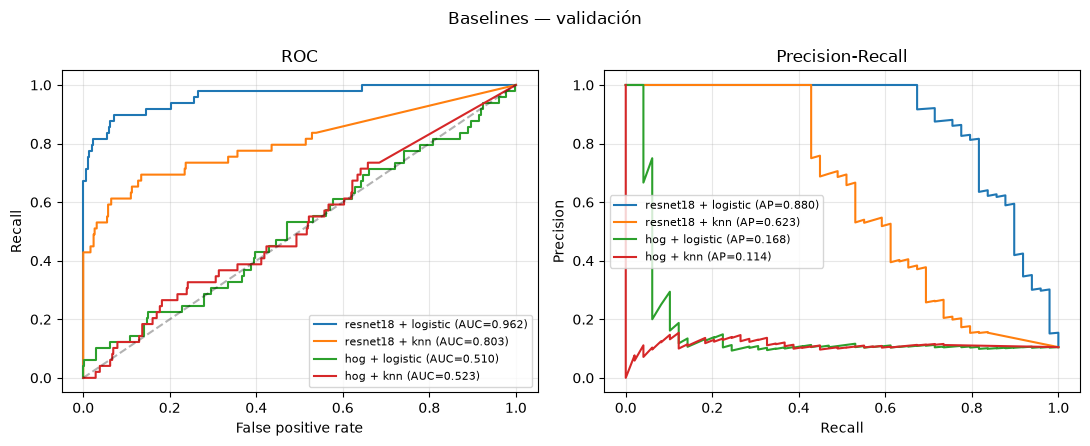

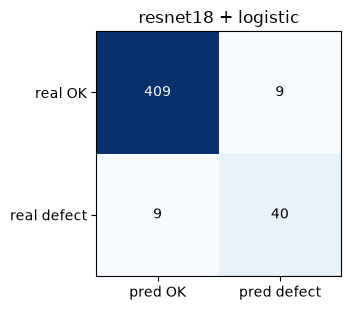

In [7]:
resnet_models = [n for n in fitted if n.startswith("resnet18")]
best_name = max(resnet_models, key=lambda n: float(val_table.loc[val_table.model == n, "avg_precision"].iloc[0]))
best = fitted[best_name]
print("Baseline oficial:", best_name, best["params"], "| umbral (max F2 en val):", round(best["threshold"], 4))
yb, sb = val_scores[best_name]
mb = evaluate(yb, sb, best["threshold"])
plot_curves(val_scores, "Baselines — validación"); plot_confusion(mb, best_name);

## 5. PCA de las features (¿se separan las defectuosas antes de entrenar nada?)

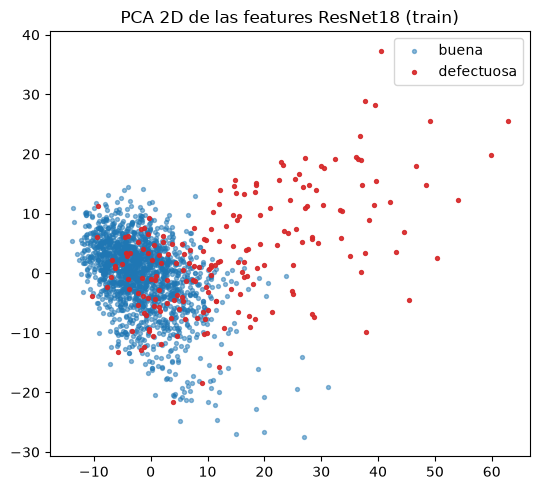

In [8]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
Xr, yr = feats["resnet18"]["train"]
Z = PCA(n_components=2, random_state=cfg["seed"]).fit_transform(StandardScaler().fit_transform(Xr))
plt.figure(figsize=(5.5, 5))
for lab, nm, col in ((0, "buena", "tab:blue"), (1, "defectuosa", "tab:red")):
    plt.scatter(*Z[yr == lab].T, s=8, alpha=0.5 if lab == 0 else 0.9, c=col, label=nm)
plt.legend(); plt.title("PCA 2D de las features ResNet18 (train)"); plt.tight_layout()

## 6. Costo del error (Práctica 5): redactar acá
- **Falso negativo** (pieza defectuosa aprobada): llega al cliente → reclamos, devoluciones, pérdida de confianza. Es el error caro.
- **Falso positivo** (pieza buena rechazada): se pierde material o tiempo de revisión; un inspector humano lo corrige. Es barato.
- Por eso se prioriza el recall y la métrica principal es F2. *(Completar con la cuantificación o el criterio que decida el equipo.)*

In [9]:
# 7) Guardar para la Fase 5 (el test se evalúa recién ahí, una sola vez)
joblib.dump(best | {"name": best_name}, CHECKPOINT_DIR / "baseline.joblib")
val_table.to_json(RESULTS_DIR / "baseline_val.json", orient="records", indent=2)
np.savez(RESULTS_DIR / "baseline_val_scores.npz", y=yb, scores=sb)
print("Guardado en", CHECKPOINT_DIR / "baseline.joblib")
if run:
    run.summary.update({"baseline/name": best_name, "baseline/val_f2": mb["f2"], "baseline/val_recall": mb["recall"]})
    run.finish()

wandb: ERROR The nbformat package was not found. It is required to save notebook history.


Guardado en /Users/ipejinakis/Documents/Ingenieria-UCA/Inteligencia Artificial/InspectIA/repo/checkpoints/baseline.joblib


hog + knn/val_ap,▁
hog + knn/val_f2,▁
hog + knn/val_recall,▁
hog + logistic/val_ap,▁
hog + logistic/val_f2,▁
hog + logistic/val_recall,▁
resnet18 + knn/val_ap,▁
resnet18 + knn/val_f2,▁
resnet18 + knn/val_recall,▁
resnet18 + logistic/val_ap,▁
+2,...
